In [1]:
# !pip install qutip
#import random
import torch as tc
import numpy as np
import qutip as qt
#import pandas as pd
#import function as my
import matplotlib.pyplot as plt
import torch.nn as nn
from torch.optim.lr_scheduler import StepLR
from tqdm import tqdm
from torch.func import jacrev, vmap, functional_call

device = tc.device("cuda" if tc.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create a small tensor and move it to GPU
x = tc.randn(1, 1).to(device)
print(f"Tensor is on: {x.device}")

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Using device: cpu
Tensor is on: cpu
Threads set to: 10


In [2]:
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1, creat_p=False, N_of_paramater=1, dropout_prob=0.0):
        super().__init__()
        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob

        # input camada linear
        self.hidden_layers = nn.ModuleList([nn.Linear(input_, neuronio[0])])
        # camadas do meio
        self.hidden_layers.extend([nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(self.neuronio)-1)])
        # Última camada linear
        self.output_layer = nn.Linear(neuronio[-1], output_)

        # Função de ativação
        self.activation_ = activation

        # Camadas de Dropout
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(self.neuronio))])

        # Criar o parâmetro
        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)
        x = self.output_layer(x)
        return x

class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)



In [3]:
tfinal      = 1
N           = 500
Nedo=16
Nfield=2

In [4]:
neuronio = [128,128]
X_vector   = Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = Nedo+Nfield,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0)
opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
opt.zero_grad(set_to_none=True)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
#index_data = np.random.randint(0,N,size=100)
# X_vector.parametro

In [5]:
#Make the calculation of all the loss functions compilable
@tc.jit.script
def calculate_all_losses(Nedo: int, y: tc.Tensor, term1: tc.Tensor, tfinal: float, tlistas: list[tc.Tensor], v0: tc.Tensor, vt: tc.Tensor):
    J22=0;J33=0;J44=6.79*3

    fp, dfp, fp0, fpt = tlistas
    
    term2 = y[:, 0:Nedo]
    Y = fp * y[:, :Nedo] + fp0 * v0[:Nedo] + fpt * vt[:Nedo]
    Y = Y.reshape(-1, 8, 2)#view(-1, 8, 2)   # (N, 8 sites, [x,y])

    X = Y[..., 0]  # (N, 8)
    Yc = Y[..., 1] # (N, 8)

    Op = y[:, Nedo:Nedo+1]   # (N,1)
    Os = y[:, Nedo+1:Nedo+2]   # (N,1)

    drift = fp * term1[:, :Nedo] + dfp * term2[:, :Nedo] + (vt[:Nedo] - v0[:Nedo]) / tfinal   # (N,16)
    drift = drift.reshape(-1, 8, 2)#view(-1, 8, 2)
    dx = drift[..., 0]
    dy = drift[..., 1]

    rhs_x = tc.zeros_like(dx)
    rhs_y = tc.zeros_like(dy)

    # indices:
    # 0→00, 1→10, 2→20, 3→30, 4→01, 5→11, 6→21, 7→31

    # ---- first 4 sites ----
    rhs_x[:,0] =  (Op[:,0] * (Yc[:,2] + Yc[:,3]))
    rhs_y[:,0] = -(Op[:,0] * (X[:,2] + X[:,3]))

    rhs_x[:,1] =  (J22 * Yc[:,1] + Os[:,0]*(Yc[:,2] - Yc[:,3]))
    rhs_y[:,1] = -(J22 * X[:,1] + Os[:,0]*(X[:,2] - X[:,3]))

    rhs_x[:,2] =  (J33 * Yc[:,2] + Op[:,0]*Yc[:,0] + Os[:,0]*Yc[:,1])
    rhs_y[:,2] = -(J33 * X[:,2] + Op[:,0]*X[:,0] + Os[:,0]*X[:,1])

    rhs_x[:,3] =  (J44 * Yc[:,3] + Op[:,0]*Yc[:,0] - Os[:,0]*Yc[:,1])
    rhs_y[:,3] = -(J44 * X[:,3] + Op[:,0]*X[:,0] - Os[:,0]*X[:,1])

    rhs_x[:,4] =  (Op[:,0] * (Yc[:,6] + Yc[:,7]))
    rhs_y[:,4] = -(Op[:,0] * (X[:,6] + X[:,7]))

    rhs_x[:,5] =  (J22 * Yc[:,5] + Os[:,0]*(Yc[:,6] - Yc[:,7]))
    rhs_y[:,5] = -(J22 * X[:,5] + Os[:,0]*(X[:,6] - X[:,7]))

    rhs_x[:,6] =  (J33 * Yc[:,6] + Op[:,0]*Yc[:,4] + Os[:,0]*Yc[:,5])
    rhs_y[:,6] = -(J33 * X[:,6] + Op[:,0]*X[:,4] + Os[:,0]*X[:,5])

    rhs_x[:,7] =  (J44 * Yc[:,7] + Op[:,0]*Yc[:,4] - Os[:,0]*Yc[:,5])
    rhs_y[:,7] = -(J44 * X[:,7] + Op[:,0]*X[:,4] - Os[:,0]*X[:,5])

    loss_edo = ((dx - rhs_x)**2 + (dy - rhs_y)**2).mean()

    ######## loss data(target conditions) #######
    target_X = tc.tensor([0, 1, 0, 0, 1, 0, 0, 0], device=X.device, dtype=X.dtype)
    target_Y = tc.zeros(8, device=Yc.device, dtype=Yc.dtype)
    X_T = X[-1]   # (8,)
    Y_T = Yc[-1]  # (8,)

    loss_cc = ((X_T - target_X)**2 + (Y_T - target_Y)**2).mean()

    ####### leakage loss #######
    idx = tc.tensor([2, 3, 6, 7], device=X.device)
    loss_state = (X[:, idx]**2 + Yc[:, idx]**2).mean()

    ####### norm loss #######
    soma1 = (X[:, :4]**2 + Yc[:, :4]**2).sum(dim=1)
    soma2 = (X[:, 4:]**2 + Yc[:, 4:]**2).sum(dim=1)
    one=tc.ones_like(soma1)#tc.ones(soma1.size()[0])
    loss_norm=(soma1-one)**2+(soma2-one)**2
    loss_norm = loss_norm.mean()

    return loss_edo, loss_cc, loss_state, loss_norm

100%|█████████████████████████████████████| 10000/10000 [02:56<00:00, 56.81it/s]


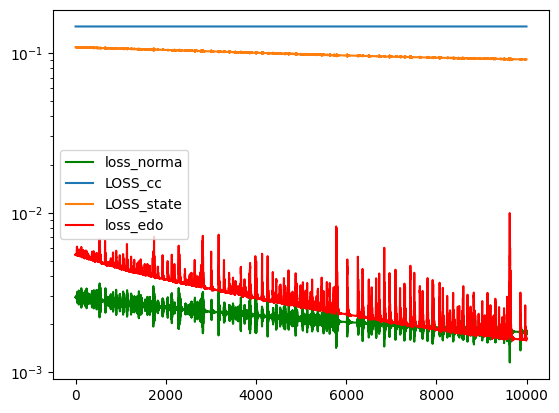

In [ ]:
epocas  = 10000
J22=0;J33=0;J44=6.79*3
LOSS    = []
LOSS1   = []
LOSS2   = []
LOSS3   = []
hisorty_of_param = []

def model_fn(t):
    return X_vector(t)

#params = dict(X_vector.named_parameters())
#def model_fn(params, t):
#    return functional_call(X_vector, params, (t,))

#porta X
SQRT12=1.0/tc.sqrt(tc.tensor(2.0))
#v0=tc.zeros(Nedo+Nfield)
#v0[0]=SQRT12
#v0[1]=SQRT12
#v0[10]=SQRT12
#v0[11]=-SQRT12
#vt=tc.zeros(Nedo+Nfield)
#vt[2]=SQRT12
#vt[3]=SQRT12
#vt[8]=SQRT12
#vt[9]=-SQRT12

#porta Hadamard
#v0=tc.zeros(Nedo+Nfield)
#v0[0]=1.0
#v0[10]=1.0
#vt=tc.zeros(Nedo+Nfield)
#vt[0]=SQRT12
#vt[2]=SQRT12
#vt[8]=SQRT12
#vt[10]=-SQRT12

#porta S
v0=tc.zeros(Nedo+Nfield)
v0[0]=SQRT12
v0[1]=SQRT12
v0[10]=SQRT12
v0[11]=-SQRT12
vt=tc.zeros(Nedo+Nfield)
vt[0]=SQRT12
vt[3]=SQRT12
vt[10]=SQRT12
vt[9]=-SQRT12

for _ in tqdm(range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)

    # Use vmap and jacrev to compute the Jacobian for every point in 'time' at once
    # This is significantly faster on both CPU and GPU
    dN_dt_full = vmap(jacrev(model_fn))(time) 
    # vectorized outputs
    #y = vmap(model_fn, in_dims=(None, 0))(params, time)

    # vectorized derivatives
    #dN_dt_full = vmap(jacrev(model_fn, argnums=1), in_dims=(None, 0))(params, time)
    dN_dt = dN_dt_full[..., 0]   # (N, Nout)
    term1 = dN_dt[:, :Nedo]

    fp=time*(tfinal-time)
    dfp=(tfinal-2*time)
    fp0=(1-time/tfinal)
    fpt=time/tfinal
    tlistas = fp, dfp, fp0, fpt

    LOSS_edo, LOSS_cc ,Loss_state, Loss_norm = calculate_all_losses(Nedo, y, term1, tfinal, tlistas, v0, vt)

    ####### Loss total #######
    loss_i = LOSS_edo + 0*LOSS_cc + 0.3*Loss_state + 0*Loss_norm

    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS1.append(LOSS_edo.cpu().detach().numpy())
    LOSS2.append(LOSS_cc.cpu().detach().numpy())
    LOSS3.append(Loss_state.cpu().detach().numpy())
    LOSS.append(Loss_norm.cpu().detach().numpy())

plt.plot(LOSS,"g",label="loss_norma")
plt.plot(LOSS2,label="LOSS_cc")
plt.plot(LOSS3,label="LOSS_state")
plt.plot(LOSS1,'r-',label="loss_edo")
plt.yscale("log")
plt.legend()
plt.show()


In [7]:
print(LOSS1[0], LOSS2[0], LOSS3[0], LOSS[0])

0.58149415 0.1464466 0.0006892202 0.33392158


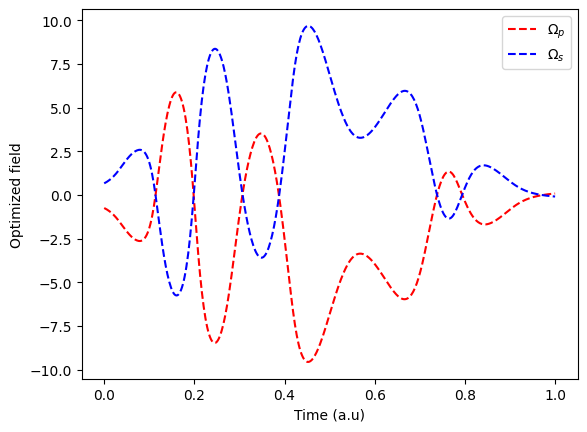

In [10]:
t_points =  np.linspace(0,tfinal, N)
# porta X
v0t=np.zeros(Nedo+Nfield)
v0t[0]=1.0/np.sqrt(2.0)
v0t[1]=1.0/np.sqrt(2.0)
v0t[10]=1.0/np.sqrt(2.0)
v0t[11]=-1.0/np.sqrt(2.0)
vtt=np.zeros(Nedo+Nfield)
vtt[2]=1.0/np.sqrt(2.0)
vtt[3]=1.0/np.sqrt(2.0)
vtt[8]=1.0/np.sqrt(2.0)
vtt[9]=-1.0/np.sqrt(2.0)

#porta Hadamard
#v0t=np.zeros(Nedo+Nfield)
#v0t[0]=1.0
#v0t[10]=1.0
#vtt=np.zeros(Nedo+Nfield)
#vtt[0]=1.0/np.sqrt(2.0)
#vtt[2]=1.0/np.sqrt(2.0)
#vtt[8]=1.0/np.sqrt(2.0)
#vtt[10]=-1.0/np.sqrt(2.0)

fpt=t_points*(tfinal-t_points)
fp0t=(1-t_points/tfinal)
fptt=t_points/tfinal

X_  = X_vector(time).detach().numpy()
plt.plot(t_points,X_[:,16],"r--", label=r'$\Omega_p$')
plt.plot(t_points,X_[:,17],"b--", label=r'$\Omega_s$')
plt.xlabel('Time (a.u)')
plt.ylabel('Optimized field')
plt.legend()
plt.show()

for k in range(Nedo):
  X_[:,k]=fpt*X_[:,k]+fp0t*v0t[k]+fptt*vtt[k]



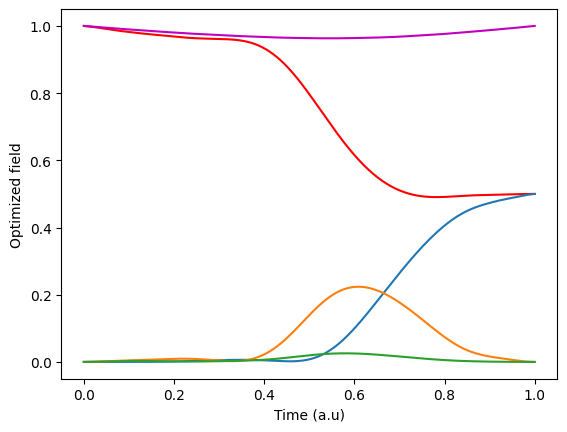

In [11]:

plt.plot(t_points,X_[:,0]**2+X_[:,1]**2, 'r')
plt.plot(t_points,X_[:,2]**2+X_[:,3]**2)
plt.plot(t_points,X_[:,4]**2+X_[:,5]**2)
plt.plot(t_points,X_[:,6]**2+X_[:,7]**2)
plt.plot(t_points,X_[:,0]**2+X_[:,1]**2+X_[:,2]**2+X_[:,3]**2+X_[:,4]**2+X_[:,5]**2+X_[:,6]**2+X_[:,7]**2, 'm')

plt.xlabel('Time (a.u)')
plt.ylabel('Optimized field')

plt.show()

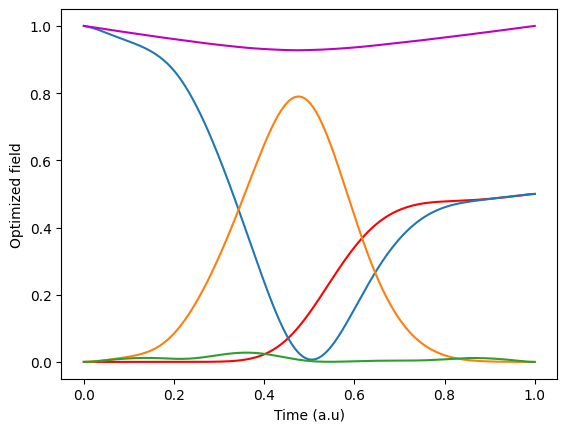

In [12]:
q=8
plt.plot(t_points,X_[:,0+q]**2+X_[:,1+q]**2, 'r')
plt.plot(t_points,X_[:,2+q]**2+X_[:,3+q]**2)
plt.plot(t_points,X_[:,4+q]**2+X_[:,5+q]**2)
plt.plot(t_points,X_[:,6+q]**2+X_[:,7+q]**2)
plt.plot(t_points,X_[:,0+q]**2+X_[:,1+q]**2+X_[:,2+q]**2+X_[:,3+q]**2+X_[:,4+q]**2+X_[:,5+q]**2+X_[:,6+q]**2+X_[:,7+q]**2, 'm')

plt.xlabel('Time (a.u)')
plt.ylabel('Optimized field')

plt.show()

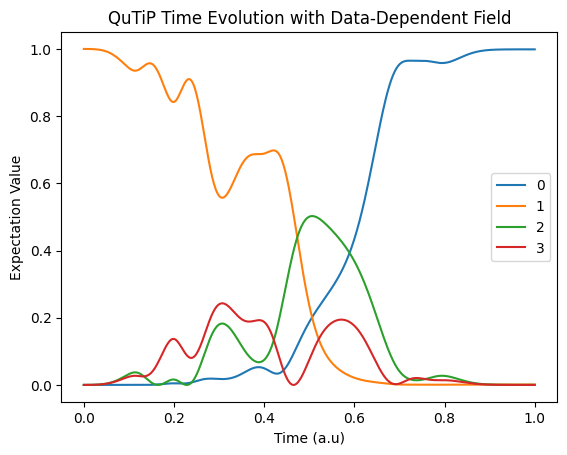

In [14]:
# QuTiP uses basis(N, n) where N is the total levels and n is the state index (starting from 0)
from qutip import *
zero = basis(4, 0)
one = basis(4, 1)
two= basis(4, 2)
three= basis(4, 3)

# Create atomic operators (projection and transition operators)
sig00 = zero * zero.dag()   # |0><0|
sig11 =one *one.dag()    # |1><1|
sig22 = two * two.dag() # |2><2|
sig33 = three * three.dag() # |3><3|
sig01 = zero * one.dag()   # |0><1|
sig02 = zero * two.dag() # |0><2|
sig12 = one * two.dag()   # |1><2|
sig21 = two * one.dag() # |2><1|
sig10 = one *zero.dag()   # |1><0|
sig20 = two *zero.dag() # |2><0|
sig03 = zero * three.dag()   # |0><3|
sig30 = three * zero.dag()   # |3><0|
sig13 = one * three.dag()   # |1><3|
sig31 = three * one.dag()   # |3><1|
H0 = J44*sig33
H1 =(sig02+sig03)+(sig20+sig30)
H2 =(sig12-sig13)+(sig21-sig31)
wp=X_[:,16]
ws=X_[:,17]
# The full Hamiltonian is defined as a list:
# H = H0 + f(t) * H1, where f(t) is the field data
H = [H0, [H1,wp], [H2,ws]] # QuTiP uses cubic spline interpolation for field_data

# (Optional) Define collapse operators for an open system simulation
c_ops = [] # e.g., c_ops = [np.sqrt(gamma) * qt.sigmam()]

# 3. Define the initial state and expectation value operators
psi0 = qt.basis(4, 1)#(qt.basis(4, 0)+qt.basis(4, 1)).unit() # Initial state |+>
e_ops = [sig00, sig11, sig22, sig33] # Operators for which to calculate expectation values
tlist= t_points

# 4. Simulate the time evolution
# Use mesolve for master equation dynamics (works for closed systems too if c_ops is empty)
result = qt.mesolve(H, psi0,tlist, c_ops,e_ops)

plt.figure()
plt.plot(t_points,result.expect[0], label='0')
plt.plot(t_points,result.expect[1], label='1')
plt.plot(t_points,result.expect[2], label='2')
plt.plot(t_points,result.expect[3], label='3')
#plt.plot(t_points[::-1],X_[:,0]**2+X_[:,1]**2, 'tab:blue', linestyle='dashed')
#plt.plot(t_points[::-1],X_[:,2]**2+X_[:,3]**2, linestyle='dashed', color='tab:orange')
#plt.plot(t_points[::-1],X_[:,4]**2+X_[:,5]**2, 'tab:green', linestyle='dashed'      )
#plt.plot(t_points[::-1],X_[:,6]**2+X_[:,7]**2, 'tab:red', linestyle='dashed')


plt.xlabel('Time (a.u)')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('QuTiP Time Evolution with Data-Dependent Field')
plt.show()


In [14]:
print(result.expect[0][-1])
print(result.expect[1][-1])

0.951631140579218
0.004482090865935177
